# Monitor — YF model *in silico* alanine scan

Builds `Xscan_ala.csv` from `TableS10_X-scan_oriDATA.xlsx`, restricted to the
**alanine substitution** at each peptide position plus the wild-type template, then compares
it against four structure predictors.

Output schema matches `260617_test_ESMFold2/benchmark/positives/AF3_class_I.csv`:

`id, cdr3_TRA, cdr3_TRB, TRAV, TRAJ, TRBV, TRBJ, species, peptide, MHC_allele_a`

plus annotation columns: **`ActivationScore`** (experimental read-out), `tcr` (source sheet),
`position` / `aa` / `mutation` (scan coordinates), `is_wt`, and `scan_row` (provenance).

**On alanine and P8.** The WT peptide is `LLWNGPMAV`, whose position 8 is already an alanine.
The source xlsx therefore holds no separate P8→A mutant: that row is the no-change control and
carries no `ActivationScore`. The scan is thus 9 positions per TCR — 8 true alanine mutants
plus the WT, which *is* the P8 alanine point. 3 TCRs x 9 = **27 rows**.

The source `Aa` column holds full residue names (`"A (Alanine)"`), so match on the leading
letter. Cysteine, not alanine, is the residue missing from the 19-aa alphabet.

**On the cognate score.** `ActivationScore` is a percentage of the cognate response, so the
wild type is 100 by definition — which is why the xlsx carries a literal `"NA"` there rather
than a measurement. Every analysis below fills it in as `COGNATE_PCT = 100.0`.

**Predictions.** Sections 4+ read the four predictor directories — `AF3/`, `ESMFold2/`,
`Protenix/`, `OpenDDE/` — each an `output.csv` with one row per (ID, seed), joined on the
`id` assigned in section 2. Seeds are collapsed per complex with `AGG` before plotting.
Add or remove a predictor by editing `MODELS` in the setup cell; a directory that is absent
is reported and skipped rather than failing the run.

In [8]:
import pandas as pd
from pathlib import Path

WD   = Path("/Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan")
XLSX = WD / "TableS10_X-scan_oriDATA.xlsx"
OUT  = WD / "Xscan_ala.csv"

# Structure predictors to compare. Key = subdirectory under WD, value = display name.
# Each holds an output.csv with one row per (ID, seed) and an iptm_pair_mean column,
# keyed on the ids this notebook assigns in section 2.
MODELS = {
    "AF3":      "AF3",
    "ESMFold2": "ESMFold2",
    "Protenix": "Protenix",
    "OpenDDE":  "OpenDDE",
}
AGG = "mean"        # per-complex aggregation over seeds; "max" = best-of-N

MHC_ALLELE_A = "HLA_A0201"
SPECIES      = "HomoSapiens"

# Keep one wild-type peptide row per TCR (ActivationScore = NA).
# For this peptide the WT row doubles as the P8 alanine point, so it is not optional
# if the alanine series is to cover all 9 positions.
INCLUDE_WT = True

# Restrict to the alanine substitutions (+ WT). Set False to rebuild the full 19-aa scan.
ALA_ONLY = True

# Per-sheet TCR chain definitions.
TCRS = {
    "TCR_YF":  dict(TRAV="TRAV12-2", cdr3_TRA="CAVGDDKIIF",  TRAJ="TRAJ30",
                    TRBV="TRBV28",   cdr3_TRB="CASTPQTAYEQYF", TRBJ="TRBJ2-7"),
    "TCR_YF2": dict(TRAV="TRAV12-2", cdr3_TRA="CAVNPDKIIF",  TRAJ="TRAJ30",
                    TRBV="TRBV4-2",  cdr3_TRB="CASSQEDRGPEKLFF", TRBJ="TRBJ1-4"),
    "TCR_YF3": dict(TRAV="TRAV12-2", cdr3_TRA="CAAGDDKIIF",  TRAJ="TRAJ30",
                    TRBV="TRBV29-1", cdr3_TRB="CSVATSGGSNEQFF", TRBJ="TRBJ2-1"),
}

# Columns matching AF3_class_I.csv, then the annotation columns.
# scan_row is the row this peptide occupies in the complete 19-aa scan — provenance only,
# nothing reads it; drop it from ANNOT_COLS if you want a leaner Xscan_ala.csv.
BASE_COLS = ["id","cdr3_TRA","cdr3_TRB","TRAV","TRAJ","TRBV","TRBJ",
             "species","peptide","MHC_allele_a"]
ANNOT_COLS = ["ActivationScore","tcr","position","aa","mutation","is_wt","scan_row"]
COLS = BASE_COLS + ANNOT_COLS

## 1. Read sheets and check assumptions

In [9]:
xl = pd.ExcelFile(XLSX)
print("sheets in file:", xl.sheet_names)

missing = set(TCRS) - set(xl.sheet_names)
assert not missing, f"sheets defined but absent from xlsx: {missing}"
extra = set(xl.sheet_names) - set(TCRS)
if extra:
    print(f"WARNING: sheets present but not defined, skipped: {sorted(extra)}")

raw = {}
for sheet in TCRS:
    df = xl.parse(sheet)
    raw[sheet] = df
    wt = df.loc[df.ActivationScore.isna(), "epitope"].unique()
    # Aa holds full names ("A (Alanine)"); match on the leading one-letter code.
    n_ala = (df.Aa.str[0] == "A").sum()
    print(f"{sheet:8s} rows={len(df):4d}  aa={df.Aa.nunique()}  pos={df.Position.nunique()}  "
          f"unique_peptides={df.epitope.nunique():4d}  NA_score={df.ActivationScore.isna().sum()}  "
          f"ala_rows={n_ala}  WT={wt}")
    assert set(df.epitope.str.len()) == {9}, f"{sheet}: non-9mer peptide present"
    assert n_ala == 9, f"{sheet}: expected one alanine row per position, got {n_ala}"

# The alanine row at the position where WT is already A carries no score (it IS the WT).
chk = raw[next(iter(TCRS))]
ala_na = chk[(chk.Aa.str[0] == "A") & chk.ActivationScore.isna()]
print(f"\nalanine rows that are the no-change control: {ala_na.Position.tolist()} "
      f"(WT residue there is already A)")
print("residues absent from the substitution alphabet:",
      sorted(set("ACDEFGHIKLMNPQRSTVWY") - set(chk.Aa.str[0])))

sheets in file: ['TCR_YF', 'TCR_YF2', 'TCR_YF3']
TCR_YF   rows= 171  aa=19  pos=9  unique_peptides= 163  NA_score=9  ala_rows=9  WT=['LLWNGPMAV']
TCR_YF2  rows= 171  aa=19  pos=9  unique_peptides= 163  NA_score=9  ala_rows=9  WT=['LLWNGPMAV']
TCR_YF3  rows= 171  aa=19  pos=9  unique_peptides= 163  NA_score=9  ala_rows=9  WT=['LLWNGPMAV']

alanine rows that are the no-change control: ['P8'] (WT residue there is already A)
residues absent from the substitution alphabet: ['C']


## 2. Assemble one table per TCR

In [10]:
records = []

for sheet, chains in TCRS.items():
    df = raw[sheet].copy()

    # Rows with no ActivationScore are the WT-for-WT substitutions -> the WT peptide.
    is_wt = df.ActivationScore.isna()
    wt_peptides = df.loc[is_wt, "epitope"].unique()
    assert len(wt_peptides) <= 1, f"{sheet}: ambiguous WT peptide {wt_peptides}"

    mut = df.loc[~is_wt, ["epitope", "ActivationScore", "Aa", "Position"]].copy()
    assert not mut.epitope.duplicated().any(), f"{sheet}: duplicated mutant peptide"
    mut["aa"]       = mut.Aa.str[0]
    mut["position"] = mut.Position.str.lstrip("P").astype(int)
    mut["is_wt"]    = False
    mut = mut.drop(columns=["Aa", "Position"])

    if INCLUDE_WT and len(wt_peptides) == 1:
        # The WT row is the alanine point at whichever position is already A.
        wt_ala_pos = df.loc[is_wt & (df.Aa.str[0] == "A"), "Position"]
        assert len(wt_ala_pos) == 1, f"{sheet}: expected exactly one WT alanine row"
        wt_row = pd.DataFrame({
            "epitope":         wt_peptides,
            "ActivationScore": pd.Series([None], dtype=mut.ActivationScore.dtype),
            "aa":              ["A"],
            "position":        [int(wt_ala_pos.iloc[0].lstrip("P"))],
            "is_wt":           [True],
        })
        mut = pd.concat([wt_row, mut], ignore_index=True)

    block = pd.DataFrame({
        "cdr3_TRA":        chains["cdr3_TRA"],
        "cdr3_TRB":        chains["cdr3_TRB"],
        "TRAV":            chains["TRAV"],
        "TRAJ":            chains["TRAJ"],
        "TRBV":            chains["TRBV"],
        "TRBJ":            chains["TRBJ"],
        "species":         SPECIES,
        "peptide":         mut.epitope.values,
        "MHC_allele_a":    MHC_ALLELE_A,
        "ActivationScore": mut.ActivationScore.values,
        "tcr":             sheet,
        "position":        mut.position.values,
        "aa":              mut.aa.values,
        "is_wt":           mut.is_wt.values,
    })
    records.append(block)
    print(f"{sheet:8s} -> {len(block):4d} rows (WT included: {INCLUDE_WT and len(wt_peptides)==1})")

full = pd.concat(records, ignore_index=True)

# Provenance only: where this peptide sits in the complete 19-aa scan. Nothing reads it.
full["scan_row"] = [f"scan_{i:04d}" for i in range(1, len(full) + 1)]
full["mutation"] = [
    "WT" if w else f"P{p}{a}" for w, p, a in zip(full.is_wt, full.position, full.aa)
]
print(f"\nfull scan: {len(full)} rows")

# Alanine subset: every row substituting A, plus the WT template (itself the P8 alanine).
xscan = full[(full.aa == "A") | full.is_wt].copy() if ALA_ONLY else full.copy()

# Order by TCRS definition order (not sheet-name alphabetical), then position.
# This ordering is what the ids are assigned over, and those ids are the key the
# prediction directories (AF3/, ESMFold2/, Protenix/, OpenDDE/) are joined on —
# so changing it invalidates every output.csv already computed.
xscan["_tcr_order"] = xscan.tcr.map({s: i for i, s in enumerate(TCRS)})
xscan = (xscan.sort_values(["_tcr_order", "position"], kind="stable")
              .drop(columns="_tcr_order")
              .reset_index(drop=True))

xscan["id"] = [f"tcr_{i:04d}" for i in range(1, len(xscan) + 1)]
xscan = xscan[COLS]

if ALA_ONLY:
    assert len(xscan) == 9 * len(TCRS), f"expected {9*len(TCRS)} rows, got {len(xscan)}"
    assert (xscan.groupby("tcr").position.nunique() == 9).all(), "a position is missing"
print(f"alanine subset: {len(xscan)} rows ({len(xscan)//len(TCRS)} per TCR)")
xscan

TCR_YF   ->  163 rows (WT included: True)
TCR_YF2  ->  163 rows (WT included: True)
TCR_YF3  ->  163 rows (WT included: True)

full scan: 489 rows
alanine subset: 27 rows (9 per TCR)


,id,cdr3_TRA,cdr3_TRB,TRAV,TRAJ,TRBV,TRBJ,species,peptide,MHC_allele_a,ActivationScore,tcr,position,aa,mutation,is_wt,scan_row
0,tcr_0001,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,ALWNGPMAV,HLA_A0201,88.92,TCR_YF,1,A,P1A,False,scan_0103
1,tcr_0002,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LAWNGPMAV,HLA_A0201,108.90,TCR_YF,2,A,P2A,False,scan_0104
2,tcr_0003,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLANGPMAV,HLA_A0201,-0.04,TCR_YF,3,A,P3A,False,scan_0105
3,tcr_0004,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWAGPMAV,HLA_A0201,0.21,TCR_YF,4,A,P4A,False,scan_0106
4,tcr_0005,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNAPMAV,HLA_A0201,35.77,TCR_YF,5,A,P5A,False,scan_0107
5,tcr_0006,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGAMAV,HLA_A0201,95.43,TCR_YF,6,A,P6A,False,scan_0108
6,tcr_0007,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPAAV,HLA_A0201,40.34,TCR_YF,7,A,P7A,False,scan_0109
7,tcr_0008,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPMAV,HLA_A0201,NaN,TCR_YF,8,A,WT,True,scan_0001
8,tcr_0009,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPMAA,HLA_A0201,92.99,TCR_YF,9,A,P9A,False,scan_0110
9,tcr_0010,CAVNPDKIIF,CASSQEDRGPEKLFF,TRAV12-2,TRAJ30,TRBV4-2,TRBJ1-4,HomoSapiens,ALWNGPMAV,HLA_A0201,13.93,TCR_YF2,1,A,P1A,False,scan_0266


## 3. Write `Xscan_ala.csv`

In [11]:
xscan.to_csv(OUT, index=False)
print("wrote", OUT, f"({len(xscan)} rows, {len(xscan.columns)} columns)")
print(OUT.read_text().split("\n")[0])

# Builder-strict variant: only the AF3_class_I.csv columns.
OUT_MIN = OUT.with_name(OUT.stem + "_min.csv")
xscan[BASE_COLS].to_csv(OUT_MIN, index=False)
print("wrote", OUT_MIN, f"({len(xscan)} rows, {len(BASE_COLS)} columns)")

pd.read_csv(OUT)

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/Xscan_ala.csv (27 rows, 17 columns)
id,cdr3_TRA,cdr3_TRB,TRAV,TRAJ,TRBV,TRBJ,species,peptide,MHC_allele_a,ActivationScore,tcr,position,aa,mutation,is_wt,scan_row
wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/Xscan_ala_min.csv (27 rows, 10 columns)


,id,cdr3_TRA,cdr3_TRB,TRAV,TRAJ,TRBV,TRBJ,species,peptide,MHC_allele_a,ActivationScore,tcr,position,aa,mutation,is_wt,scan_row
0,tcr_0001,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,ALWNGPMAV,HLA_A0201,88.92,TCR_YF,1,A,P1A,False,scan_0103
1,tcr_0002,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LAWNGPMAV,HLA_A0201,108.90,TCR_YF,2,A,P2A,False,scan_0104
2,tcr_0003,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLANGPMAV,HLA_A0201,-0.04,TCR_YF,3,A,P3A,False,scan_0105
3,tcr_0004,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWAGPMAV,HLA_A0201,0.21,TCR_YF,4,A,P4A,False,scan_0106
4,tcr_0005,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNAPMAV,HLA_A0201,35.77,TCR_YF,5,A,P5A,False,scan_0107
5,tcr_0006,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGAMAV,HLA_A0201,95.43,TCR_YF,6,A,P6A,False,scan_0108
6,tcr_0007,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPAAV,HLA_A0201,40.34,TCR_YF,7,A,P7A,False,scan_0109
7,tcr_0008,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPMAV,HLA_A0201,NaN,TCR_YF,8,A,WT,True,scan_0001
8,tcr_0009,CAVGDDKIIF,CASTPQTAYEQYF,TRAV12-2,TRAJ30,TRBV28,TRBJ2-7,HomoSapiens,LLWNGPMAA,HLA_A0201,92.99,TCR_YF,9,A,P9A,False,scan_0110
9,tcr_0010,CAVNPDKIIF,CASSQEDRGPEKLFF,TRAV12-2,TRAJ30,TRBV4-2,TRBJ1-4,HomoSapiens,ALWNGPMAV,HLA_A0201,13.93,TCR_YF2,1,A,P1A,False,scan_0266


---

# Analysis of the predictions

Four structure predictors were run on the same 27 alanine complexes, each with **3 seeds**
(1000/1001/1002), one sample per seed — 81 rows per `output.csv`:

| directory | rows | per complex |
|---|---|---|
| `AF3/` | 81 | 3 seeds |
| `ESMFold2/` | 81 | 3 seeds |
| `Protenix/` | 81 | 3 seeds |
| `OpenDDE/` | 81 | 3 seeds |

All four are keyed on `xscan.id` (`tcr_0001` … `tcr_0027`) and their `input.csv` peptides
match `Xscan_ala.csv` exactly. Seeds are collapsed per complex with `AGG` (set in the setup
cell; `"mean"` by default, `"max"` for best-of-N) before anything is plotted — otherwise each
peptide would enter the statistics three times.

Note that the four predictors sit on **very different ipTM ranges** (ESMFold2 ≈ 0.68–0.80,
OpenDDE ≈ 0.77–0.96), so scores are never compared across models on a shared axis, and
correlations are always evaluated within a single TCR of a single model.

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/fig_alanine_scan.pdf


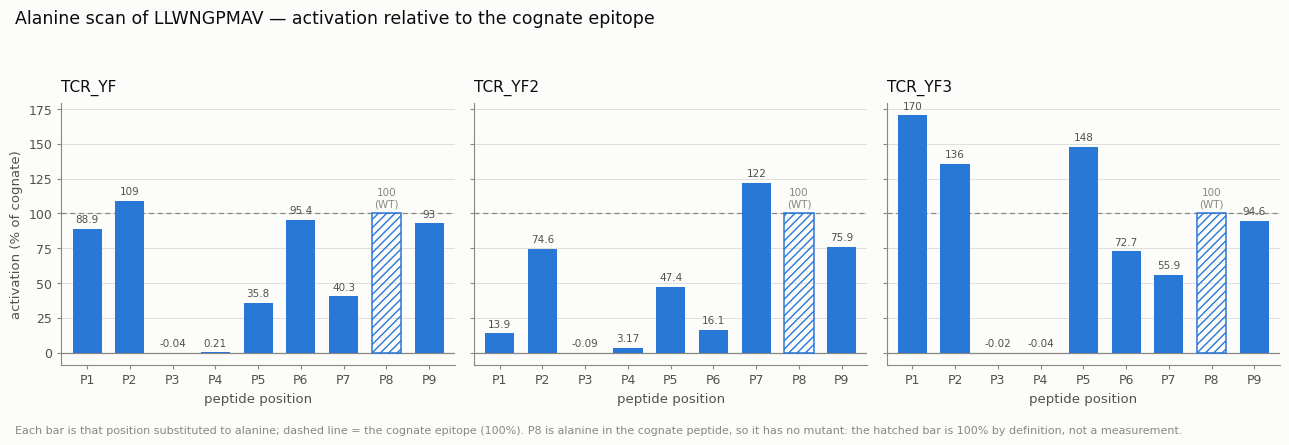

In [12]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

ANNOTATE    = "all"      # "all" | "none"
COGNATE_PCT = 100.0      # ActivationScore is a % of the cognate response
FIG_OUT     = WD / "fig_alanine_scan.pdf"

SERIES, SURFACE, INK, INK_2, MUTED = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
N_POS = 9

fig, axes = plt.subplots(1, len(TCRS), figsize=(13, 4.3), sharey=True)
fig.patch.set_facecolor(SURFACE)

for ax, sheet in zip(axes, TCRS):
    d = (xscan[xscan.tcr == sheet].sort_values("position")
         .set_index("position").reindex(range(1, N_POS + 1)))
    wt = d.is_wt.fillna(False).to_numpy(dtype=bool)
    # ActivationScore is a % of the cognate response -> the WT point is 100 by definition.
    score = d.ActivationScore.where(~wt, COGNATE_PCT)
    ax.set_facecolor(SURFACE)

    ax.axhline(COGNATE_PCT, color=MUTED, linewidth=0.9, linestyle=(0, (4, 3)), zorder=2)
    ax.bar(d.index[~wt], score[~wt], width=0.68, color=SERIES, linewidth=0, zorder=3)
    # Definitional, not measured -> hatched outline so it never reads as a data point.
    ax.bar(d.index[wt], score[wt], width=0.68, facecolor="none", edgecolor=SERIES,
           linewidth=1.1, hatch="////", zorder=3)

    if ANNOTATE != "none":
        for p, v, is_w in zip(d.index, score, wt):
            if pd.isna(v):
                continue
            ax.annotate("100\n(WT)" if is_w else f"{v:.3g}", (p, v),
                        xytext=(0, 3), textcoords="offset points", ha="center",
                        va="bottom", fontsize=7.5, linespacing=1.2,
                        color=MUTED if is_w else INK_2)

    ax.axhline(0, color=MUTED, linewidth=0.9, zorder=2)
    ax.set_title(sheet, fontsize=11, color=INK, pad=9, loc="left")
    ax.set_xticks(range(1, N_POS + 1))
    ax.set_xticklabels([f"P{p}" for p in range(1, N_POS + 1)])
    ax.set_xlabel("peptide position", fontsize=9.5, color=INK_2)
    ax.set_xlim(0.4, N_POS + 0.6)
    ax.grid(axis="y", color=MUTED, alpha=0.25, linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_color(INK_2)

axes[0].set_ylabel("activation (% of cognate)", fontsize=9.5, color=INK_2)

fig.suptitle("Alanine scan of LLWNGPMAV — activation relative to the cognate epitope",
             fontsize=12.5, color=INK, x=0.015, ha="left", y=0.99)
fig.text(0.015, 0.005,
         "Each bar is that position substituted to alanine; dashed line = the cognate "
         "epitope (100%). P8 is alanine in the cognate peptide, so it has no mutant: "
         "the hatched bar is 100% by definition, not a measurement.",
         fontsize=8, color=MUTED, ha="left")

fig.tight_layout(rect=(0, 0.035, 1, 0.94))
fig.savefig(FIG_OUT, facecolor=SURFACE, bbox_inches="tight")
print("wrote", FIG_OUT)
plt.show()

108 rows | 4 models x 27 complexes | seeds/complex: [np.int64(3)] aggregated by mean
seed spread in iptm_pair_mean (median SD over complexes):
   AF3        0.0175
   ESMFold2   0.0113
   Protenix   0.0109
   OpenDDE    0.0021

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/fig_activation_vs_iptm_pair_mean_mean.pdf


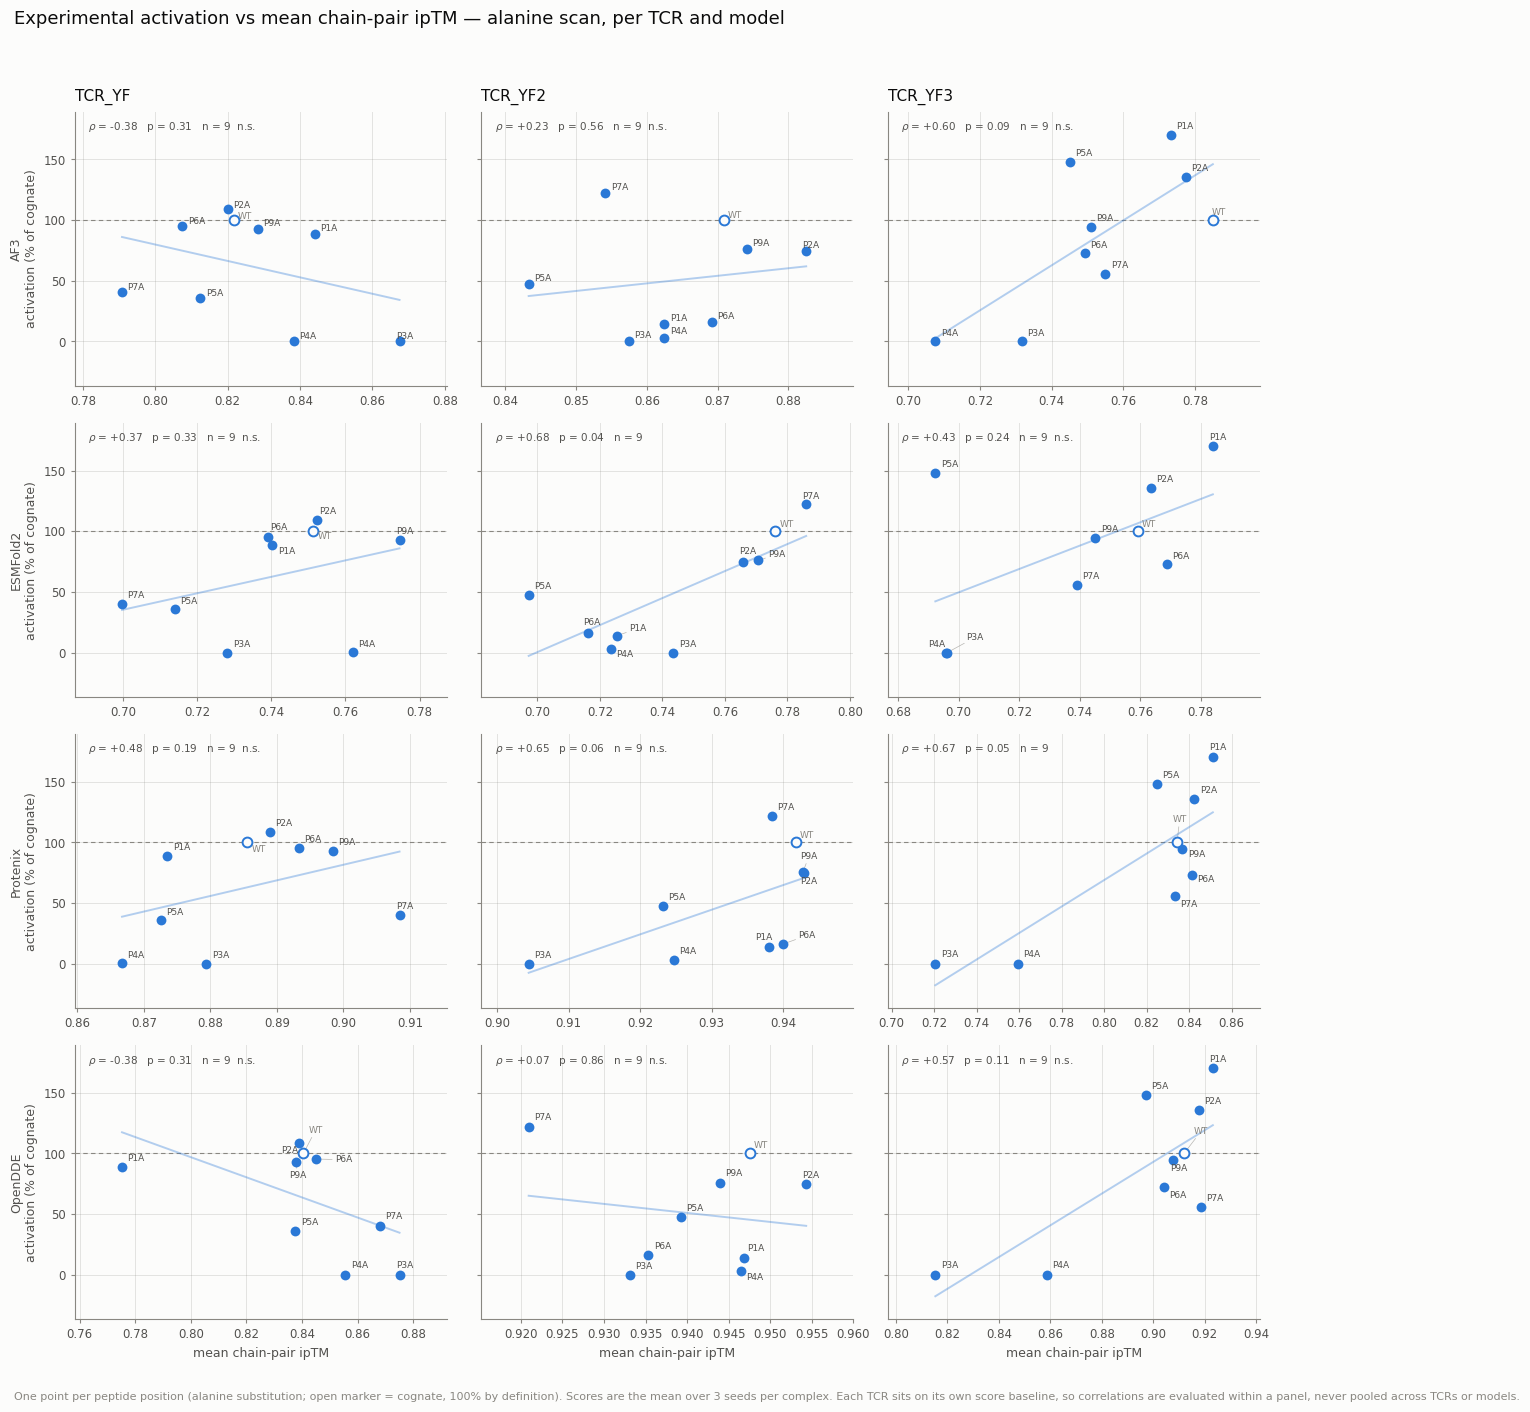

In [13]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr
from adjustText import adjust_text
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

METRIC      = "iptm_pair_mean"
METRIC_LAB  = "mean chain-pair ipTM"
COGNATE_PCT = 100.0
LABEL_PTS   = True
FIG_OUT     = WD / f"fig_activation_vs_{METRIC}_{AGG}.pdf"

SERIES, SURFACE, INK, INK_2, MUTED = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#898781"

# --- load every model, aggregating the seed replicates per complex -----------------
frames = []
for mdir, mname in MODELS.items():
    p = WD / mdir / "output.csv"
    if not p.exists():
        print(f"  missing: {p.relative_to(WD)}")
        continue
    o = pd.read_csv(p)
    agg = (o.groupby("ID")[METRIC]
             .agg([AGG, "std", "size"])
             .rename(columns={AGG: "score", "std": "score_sd", "size": "n_seeds"})
             .reset_index())
    d = xscan.merge(agg, left_on="id", right_on="ID", how="inner")
    assert len(d) == len(xscan), f"{mname}: {len(d)}/{len(xscan)} rows matched"
    d["model"] = mname
    frames.append(d)

dat = pd.concat(frames, ignore_index=True)
dat["act"] = dat.ActivationScore.fillna(COGNATE_PCT)   # cognate = 100 by definition
models = [m for m in MODELS.values() if m in set(dat.model)]
print(f"{len(dat)} rows | {len(models)} models x {len(xscan)} complexes "
      f"| seeds/complex: {sorted(dat.n_seeds.unique())} aggregated by {AGG}")
print(f"seed spread in {METRIC} (median SD over complexes):")
for m in models:
    print(f"   {m:10s} {dat.loc[dat.model == m, 'score_sd'].median():.4f}")

# --- grid: one row per model, one column per TCR ------------------------------------
sheets = list(TCRS)
fig, axes = plt.subplots(len(models), len(sheets),
                         figsize=(4.3 * len(sheets), 3.5 * len(models)),
                         sharey=True, squeeze=False)
fig.patch.set_facecolor(SURFACE)

for r, mname in enumerate(models):
    for c, sheet in enumerate(sheets):
        ax = axes[r][c]
        g = dat[(dat.model == mname) & (dat.tcr == sheet)]
        ax.set_facecolor(SURFACE)
        ax.axhline(COGNATE_PCT, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)), zorder=1)

        rho, p = spearmanr(g.act, g.score)
        xs = np.linspace(g.score.min(), g.score.max(), 2)
        b, a = np.polyfit(g.score, g.act, 1)
        ax.plot(xs, b * xs + a, color=SERIES, alpha=0.35, linewidth=1.4, zorder=2)

        mut, wt = g[~g.is_wt], g[g.is_wt]
        ax.scatter(mut.score, mut.act, s=50, color=SERIES, linewidth=0, zorder=4)
        # Cognate: y is 100 by definition, not a measurement -> open marker.
        ax.scatter(wt.score, wt.act, s=50, facecolor=SURFACE, edgecolor=SERIES,
                   linewidth=1.4, zorder=4)

        if LABEL_PTS:
            texts = [ax.text(rr.score, rr.act, rr.mutation, fontsize=6.5, zorder=5,
                             color=MUTED if rr.is_wt else INK_2)
                     for _, rr in g.iterrows()]
            adjust_text(texts, ax=ax, expand=(1.5, 1.7), force_text=(0.4, 0.6),
                        arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5, alpha=0.6))

        sig = "" if p < 0.05 else "  n.s."
        ax.annotate(f"$\\rho$ = {rho:+.2f}   p = {p:.2f}   n = {len(g)}{sig}",
                    (0.035, 0.97), xycoords="axes fraction", va="top", ha="left",
                    fontsize=7.5, color=INK_2)

        if r == 0:
            ax.set_title(sheet, fontsize=11, color=INK, pad=8, loc="left")
        if r == len(models) - 1:
            ax.set_xlabel(METRIC_LAB, fontsize=9, color=INK_2)
        if c == 0:
            ax.set_ylabel(f"{mname}\nactivation (% of cognate)", fontsize=9, color=INK_2)
        ax.grid(color=MUTED, alpha=0.22, linewidth=0.7, zorder=0)
        ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
        ax.tick_params(colors=MUTED, labelsize=8.5, length=3)
        ax.margins(x=0.17, y=0.10)
        for t in ax.get_xticklabels() + ax.get_yticklabels():
            t.set_color(INK_2)

fig.suptitle(f"Experimental activation vs {METRIC_LAB} — alanine scan, per TCR and model",
             fontsize=13, color=INK, x=0.015, ha="left", y=0.997)
fig.text(0.015, 0.004,
         f"One point per peptide position (alanine substitution; open marker = cognate, "
         f"100% by definition). Scores are the {AGG} over {int(dat.n_seeds.median())} seeds "
         f"per complex. Each TCR sits on its own score baseline, so correlations are "
         f"evaluated within a panel, never pooled across TCRs or models.",
         fontsize=8, color=MUTED, ha="left")

fig.tight_layout(rect=(0, 0.022, 1, 0.975))
fig.savefig(FIG_OUT, facecolor=SURFACE, bbox_inches="tight")
print("\nwrote", FIG_OUT)
plt.show()

scored: 108 rows | 4 models x 27 complexes (mean over seeds) | threshold 50%

class    binder  non-binder
tcr                        
TCR_YF       20          16
TCR_YF2      16          20
TCR_YF3      28           8

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/benchmark_iptm_pair_mean_mean_thr50.pdf


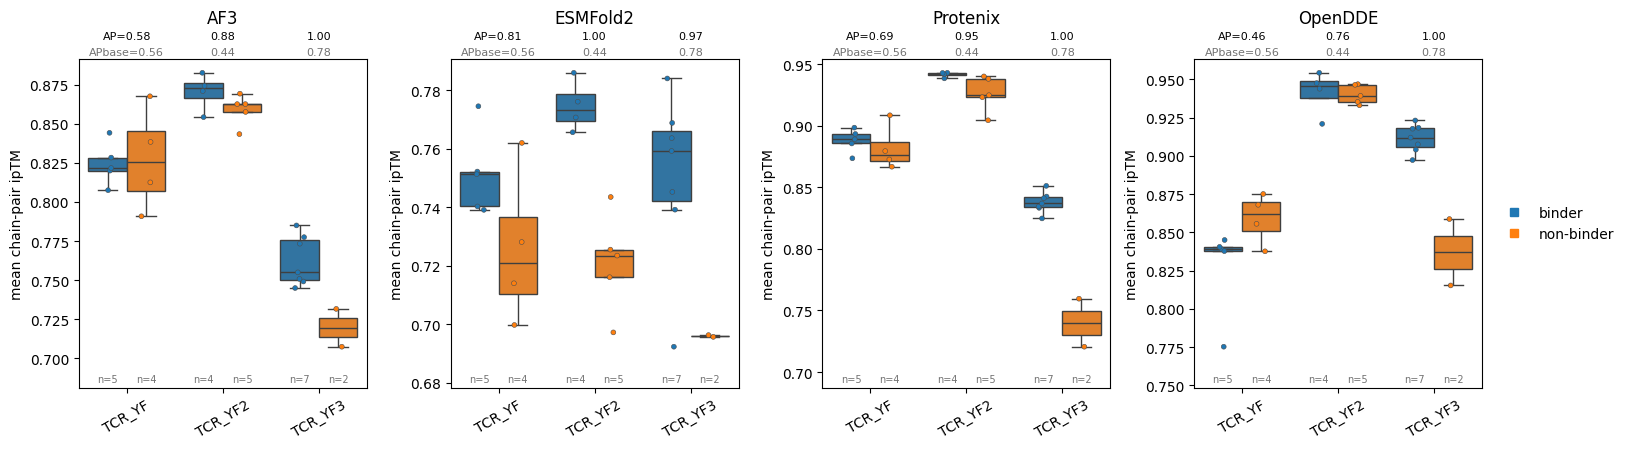

In [14]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import average_precision_score
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

# ---- binder definition ----------------------------------------------------
BINDER_THRESHOLD_PCT = 50.0   # ActivationScore >= this (% of cognate) == binder

SCORE      = "iptm_pair_mean"
SCORE_LAB  = "mean chain-pair ipTM"
TCR_ORDER  = list(TCRS)
FIG_OUT    = WD / f"benchmark_{SCORE}_{AGG}_thr{BINDER_THRESHOLD_PCT:g}.pdf"

# ---- predictions: one row per (model, complex), seeds aggregated -----------
rec = []
for mdir, mname in MODELS.items():
    p = WD / mdir / "output.csv"
    if not p.exists():
        print(f"  missing: {p.relative_to(WD)}")
        continue
    d = (pd.read_csv(p).groupby("ID")[SCORE].agg(AGG).rename("score").reset_index())
    d["model"] = mname
    rec.append(d)
pred = pd.concat(rec, ignore_index=True).merge(xscan, left_on="ID", right_on="id", how="inner")
pred["act"]   = pred.ActivationScore.fillna(100.0)      # cognate = 100 by definition
pred["label"] = (pred.act >= BINDER_THRESHOLD_PCT).astype(int)
pred["class"] = np.where(pred.label == 1, "binder", "non-binder")
models = [m for m in MODELS.values() if m in set(pred.model)]
print(f"scored: {len(pred)} rows | {len(models)} models x {pred.ID.nunique()} complexes "
      f"({AGG} over seeds) | threshold {BINDER_THRESHOLD_PCT:g}%\n")
print(pd.crosstab(pred.tcr, pred["class"]).loc[TCR_ORDER].to_string())

# ---- plot: one panel per model --------------------------------------------
PAL = {"binder": "#1f77b4", "non-binder": "#ff7f0e"}
HUE = ["binder", "non-binder"]
# NOT sharey: the models sit on very different ipTM ranges, and a shared scale
# pushes whole boxes off-axis.
fig, axes = plt.subplots(1, len(models), figsize=(4.1 * len(models), 4.6),
                         sharey=False, squeeze=False)
axes = axes[0]

for ax, mname in zip(axes, models):
    g = pred[pred.model == mname]
    sns.boxplot(data=g, x="tcr", y="score", hue="class", order=TCR_ORDER,
                hue_order=HUE, palette=PAL, showfliers=False, ax=ax)
    sns.stripplot(data=g, x="tcr", y="score", hue="class", order=TCR_ORDER,
                  hue_order=HUE, palette=PAL, dodge=True, size=3.5,
                  edgecolor="0.3", linewidth=0.4, legend=False, ax=ax)

    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - (hi - lo) * 0.09, hi)      # clear strip for the n labels

    for i, t in enumerate(TCR_ORDER):
        s = g[g.tcr == t]
        base = s.label.mean()                   # AP of a random ranker
        ap = average_precision_score(s.label, s.score) if s.label.nunique() > 1 else np.nan
        pre  = "AP=" if i == 0 else ""
        pre2 = "APbase=" if i == 0 else ""
        ax.text(i, 1.055, f"{pre}{ap:.2f}", ha="center", va="bottom",
                transform=ax.get_xaxis_transform(), fontsize=8)
        ax.text(i, 1.005, f"{pre2}{base:.2f}", ha="center", va="bottom",
                transform=ax.get_xaxis_transform(), fontsize=8, color="0.45")
        # n per box: with so few alanine points a "box" can rest on 2 values - say so.
        for j, cls in enumerate(HUE):
            ax.text(i + (j - 0.5) * 0.4, 0.012, f"n={(s['class'] == cls).sum()}",
                    ha="center", va="bottom", transform=ax.get_xaxis_transform(),
                    fontsize=7, color="0.45")

    ax.set_title(mname, pad=26)
    ax.set_xlabel("")
    ax.set_ylabel(SCORE_LAB)
    ax.tick_params(axis="x", rotation=30)
    ax.get_legend().remove()

h = [plt.Line2D([], [], marker="s", ls="", color=PAL[c], label=c) for c in PAL]
axes[-1].legend(handles=h, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
fig.savefig(FIG_OUT, bbox_inches="tight")
print(f"\nwrote {FIG_OUT}")
plt.show()

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/fig_alanine_ESMFold2_iptm_pair_mean_delta.pdf


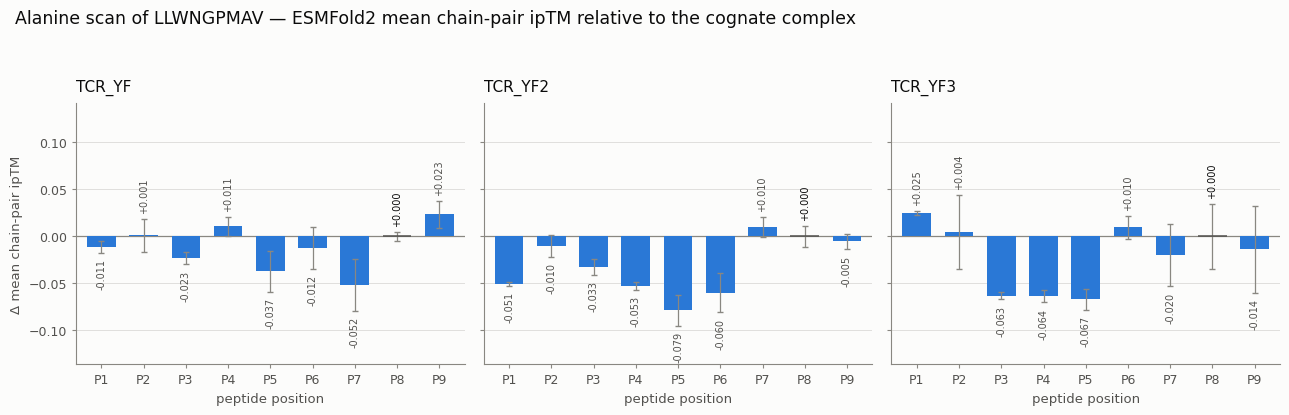

In [18]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

ANNOTATE  = "all"            # "all" | "none"
MODEL     = "ESMFold2"
SCORE     = "iptm_pair_mean"
SCORE_LAB = "mean chain-pair ipTM"
DELTA     = True            # True = plot the change vs the cognate complex
SHOW_SD   = True             # error bars = SD over the 3 seeds
FIG_OUT   = WD / f"fig_alanine_{MODEL}_{SCORE}{'_delta' if DELTA else ''}.pdf"

SERIES, SURFACE, INK, INK_2, MUTED = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
N_POS = 9

# Seeds collapsed per complex; keep the spread so it can be drawn.
_o = pd.read_csv(WD / MODEL / "output.csv")
_agg = (_o.groupby("ID")[SCORE].agg([AGG, "std"])
          .rename(columns={AGG: "score", "std": "score_sd"}).reset_index())
sdat = xscan.merge(_agg, left_on="id", right_on="ID", how="inner")
assert len(sdat) == len(xscan), f"{MODEL}: {len(sdat)}/{len(xscan)} rows matched"

fig, axes = plt.subplots(1, len(TCRS), figsize=(13, 4.3), sharey=True)
fig.patch.set_facecolor(SURFACE)

for ax, sheet in zip(axes, TCRS):
    d = (sdat[sdat.tcr == sheet].sort_values("position")
         .set_index("position").reindex(range(1, N_POS + 1)))
    wt = d.is_wt.fillna(False).to_numpy(dtype=bool)
    cognate = d.score[wt].iloc[0]
    # Unlike ActivationScore, the cognate ipTM IS a prediction like any other -> solid bar.
    score = d.score - cognate if DELTA else d.score
    err = d.score_sd if SHOW_SD else None
    ax.set_facecolor(SURFACE)

    if not DELTA:
        ax.axhline(cognate, color=MUTED, linewidth=0.9, linestyle=(0, (4, 3)), zorder=2)
    ax.bar(d.index, score, width=0.68, color=SERIES, linewidth=0, zorder=3,
           yerr=err, error_kw=dict(ecolor=MUTED, elinewidth=0.9, capsize=2))
    # The cognate is marked, not hidden: same measurement, reference role.
    ax.bar(d.index[wt], score[wt], width=0.68, facecolor=SERIES, edgecolor=INK_2,
           linewidth=1.1, zorder=4)

    if ANNOTATE != "none":
        for p, v, e, is_w in zip(d.index, score, d.score_sd, wt):
            if pd.isna(v):
                continue
            # Anchor past the error bar and push outward in the bar's own direction.
            cap = 0.0 if (pd.isna(e) or not SHOW_SD) else e
            up = v >= 0
            ax.annotate(f"{v:+.3f}" if DELTA else f"{v:.3f}",
                        (p, v + cap if up else v - cap),
                        xytext=(0, 4 if up else -4), textcoords="offset points",
                        ha="center", va="bottom" if up else "top",
                        fontsize=7, rotation=90,
                        color=INK if is_w else INK_2)

    ax.axhline(0, color=MUTED, linewidth=0.9, zorder=2)
    ax.set_title(sheet, fontsize=11, color=INK, pad=9, loc="left")
    ax.set_xticks(range(1, N_POS + 1))
    ax.set_xticklabels([f"P{p}" for p in range(1, N_POS + 1)])
    ax.set_xlabel("peptide position", fontsize=9.5, color=INK_2)
    ax.set_xlim(0.4, N_POS + 0.6)
    ax.grid(axis="y", color=MUTED, alpha=0.25, linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_color(INK_2)

for ax in axes:                      # room for the rotated value labels
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - (hi - lo) * 0.06, hi + (hi - lo) * 0.16)
axes[0].set_ylabel(f"{'Δ ' if DELTA else ''}{SCORE_LAB}", fontsize=9.5, color=INK_2)

fig.suptitle(f"Alanine scan of LLWNGPMAV — {MODEL} {SCORE_LAB}"
             f"{' relative to the cognate complex' if DELTA else ''}",
             fontsize=12.5, color=INK, x=0.015, ha="left", y=0.99)

fig.tight_layout(rect=(0, 0.035, 1, 0.94))
fig.savefig(FIG_OUT, facecolor=SURFACE, bbox_inches="tight")
print("wrote", FIG_OUT)
plt.show()

wrote /Users/roessner/Documents/PostDoc/Data/261011_MD_YF_Xscan/fig_alanine_activation_delta.pdf


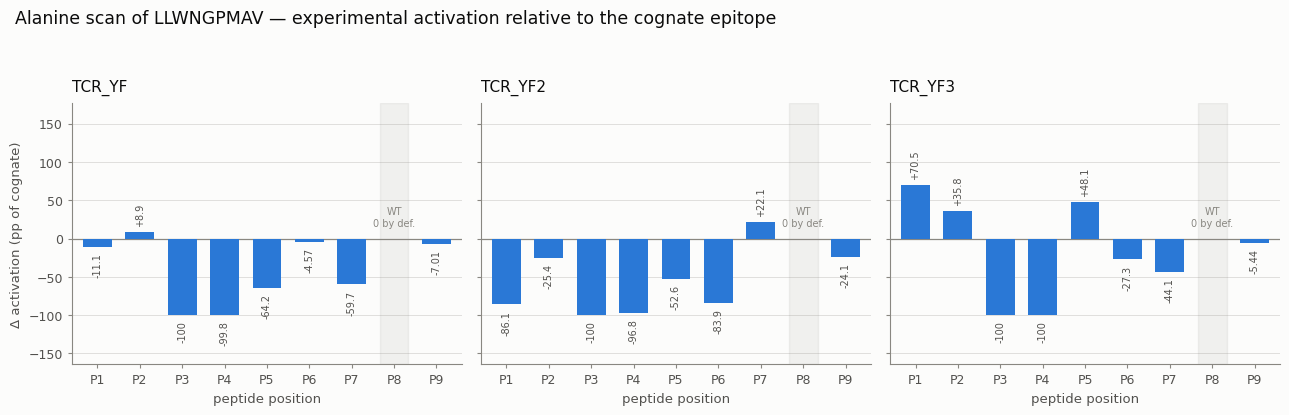

In [19]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

ANNOTATE    = "all"        # "all" | "none"
COGNATE_PCT = 100.0        # ActivationScore is a % of the cognate response
DELTA       = True         # True = change vs the cognate; False = raw % of cognate
FIG_OUT     = WD / f"fig_alanine_activation{'_delta' if DELTA else ''}.pdf"

SERIES, SURFACE, INK, INK_2, MUTED = "#2a78d6", "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
N_POS = 9

fig, axes = plt.subplots(1, len(TCRS), figsize=(13, 4.3), sharey=True)
fig.patch.set_facecolor(SURFACE)

for ax, sheet in zip(axes, TCRS):
    d = (xscan[xscan.tcr == sheet].sort_values("position")
         .set_index("position").reindex(range(1, N_POS + 1)))
    wt = d.is_wt.fillna(False).to_numpy(dtype=bool)
    act = d.ActivationScore.where(~wt, COGNATE_PCT)   # cognate = 100 by definition
    score = act - COGNATE_PCT if DELTA else act
    ax.set_facecolor(SURFACE)

    if not DELTA:
        ax.axhline(COGNATE_PCT, color=MUTED, linewidth=0.9, linestyle=(0, (4, 3)), zorder=2)
    ax.bar(d.index[~wt], score[~wt], width=0.68, color=SERIES, linewidth=0, zorder=3)

    # The cognate carries no measurement: it is 100 (so Delta = 0) by definition. Under
    # DELTA that bar has zero height and cannot be drawn - mark the slot instead.
    for p, v in zip(d.index[wt], score[wt]):
        if DELTA:
            ax.axvspan(p - 0.34, p + 0.34, color=MUTED, alpha=0.10, zorder=1)
            ax.annotate("WT\n0 by def.", (p, 0), xytext=(0, 7),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=7, color=MUTED, linespacing=1.3)
        else:
            ax.bar([p], [v], width=0.68, facecolor="none", edgecolor=SERIES,
                   linewidth=1.1, hatch="////", zorder=3)
            ax.annotate("100\n(WT)", (p, v), xytext=(0, 4), textcoords="offset points",
                        ha="center", va="bottom", fontsize=7, color=MUTED, linespacing=1.3)

    if ANNOTATE != "none":
        for p, v, is_w in zip(d.index, score, wt):
            if pd.isna(v) or is_w:
                continue
            up = v >= 0
            ax.annotate(f"{v:+.3g}" if DELTA else f"{v:.3g}", (p, v),
                        xytext=(0, 4 if up else -4), textcoords="offset points",
                        ha="center", va="bottom" if up else "top",
                        fontsize=7, rotation=90, color=INK_2)

    ax.axhline(0, color=MUTED, linewidth=0.9, zorder=2)
    ax.set_title(sheet, fontsize=11, color=INK, pad=9, loc="left")
    ax.set_xticks(range(1, N_POS + 1))
    ax.set_xticklabels([f"P{p}" for p in range(1, N_POS + 1)])
    ax.set_xlabel("peptide position", fontsize=9.5, color=INK_2)
    ax.set_xlim(0.4, N_POS + 0.6)
    ax.grid(axis="y", color=MUTED, alpha=0.25, linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelsize=9, length=3)
    for t in ax.get_xticklabels() + ax.get_yticklabels():
        t.set_color(INK_2)

for ax in axes:                      # room for the rotated value labels
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo - (hi - lo) * 0.08, hi + (hi - lo) * 0.14)
axes[0].set_ylabel(("Δ activation (pp of cognate)" if DELTA
                    else "activation (% of cognate)"), fontsize=9.5, color=INK_2)

fig.suptitle("Alanine scan of LLWNGPMAV — experimental activation"
             f"{' relative to the cognate epitope' if DELTA else ''}",
             fontsize=12.5, color=INK, x=0.015, ha="left", y=0.99)

fig.tight_layout(rect=(0, 0.035, 1, 0.94))
fig.savefig(FIG_OUT, facecolor=SURFACE, bbox_inches="tight")
print("wrote", FIG_OUT)
plt.show()